---
title: "Titanic's Survivor Prediction"
description: " "
date: 2023-06-20
categories: [Deep Learning, Classification]
image: images/titanic.png
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../home.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Titanic's Survivor Prediction</li>
</ol>

## Overview

This notebook investigates the implementation of artificial neural network (ANN) models to classify whether the titanic's passenger survived or not using the following dataset.

[<i class="bi bi-download"></i> Download Dataset (.csv)](data/titanic.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis covers these main steps:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Model training
3. Model evaluation

The primary objective of this notebook is to perform an end-to-end machine learning process and implement a simple perceptron model.

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib numpy pandas scikit-learn tensorflow

In [109]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

## Load Dataset

In [110]:
df = pd.read_csv('data/titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Data Preprocessing and EDA

Let's take a look at the overview of the dataset.

In [111]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Based on the output above, here are some informations about the dataset.
- The dataset has 891 rows and 12 columns.
- The target variable is 'Survived'.
- The features consist of both numerical and categorical features.
- Notice that there are some features with missing values.

Let's also see the distribution of the target variable (Survived).

In [112]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: xlabel='Survived'>

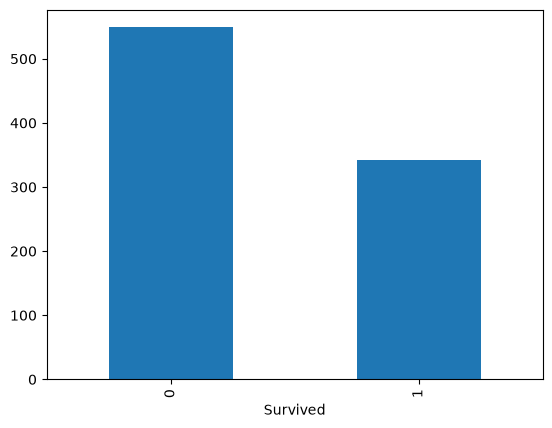

In [113]:
df['Survived'].value_counts().plot(kind='bar')

### Drop Unnecessary Columns

We need to drop some columns:
- **PassengerId** because it is equal/similar to the index
- **Name**
- **Ticket**

In [114]:
df = df.drop(columns=['PassengerId', 'Name', 'Ticket'])

### Check and Drop Duplicates (If Exist)

In [115]:
# check and drop duplicated rows (if exist)
total_duplicates = df.duplicated().sum()
print(f'Total duplicated rows: {total_duplicates}')
if total_duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
    print('All duplicated rows has been removed.')
else:
    print('No duplicated rows need to be dropped.')

Total duplicated rows: 107
All duplicated rows has been removed.


In [116]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
779,0,3,female,39.0,0,5,29.1250,NaN,Q
780,1,1,female,19.0,0,0,30.0000,B42,S
781,0,3,female,NaN,1,2,23.4500,NaN,S
782,1,1,male,26.0,0,0,30.0000,C148,C


### Handling Missing Values

Let's check again the missing values for each column.

In [117]:
print('Missing values for each column:')
df.isna().sum()

Missing values for each column:


Survived      0
Pclass        0
Sex           0
Age         106
SibSp         0
Parch         0
Fare          0
Cabin       581
Embarked      2
dtype: int64

There are 3 columns with missing values: **Age**, **Cabin**, and **Embarked**.

<Axes: >

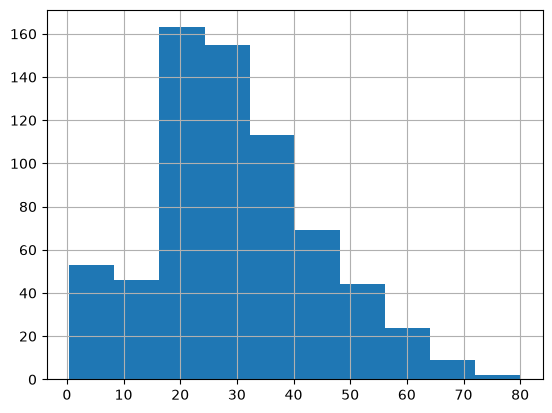

In [118]:
df['Age'].hist()

In [119]:
df['Cabin'].value_counts()

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64

<Axes: xlabel='Embarked'>

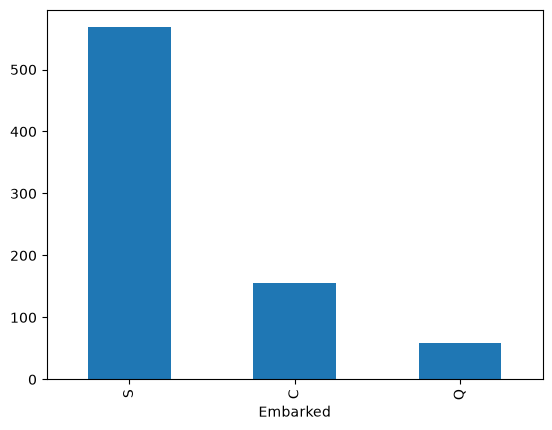

In [120]:
df['Embarked'].value_counts().plot(kind='bar')

Handling missing values startegy:

- The Cabin column exhibits an exceptionally high percentage of missing data (over 77% missing values across the dataset). Furthermore, the non-missing entries consist of highly sparse alphanumeric string values representing specific room identifiers. Attempting to impute such a large volume of missing records would introduce severe synthetic bias, while converting the high-cardinality string values would needlessly inflate feature dimensionality. Consequently, the **Cabin feature need to be dropped entirely** to preserve model efficiency and dataset integrity.

- Missing values in the **Age feature were imputed using the dataset's median** value rather than the mean. Age exhibits a right-skewed distribution with notable presence of outliers (e.g., elderly passengers and young infants). Using median imputation ensures robust central tendency substitution that is not skewed by extreme values, preserving the underlying numerical distribution without dropping valuable passenger records.

- **The Embarked feature** is a categorical variable representing the port of embarkation, containing only a minimal number of missing instances (2 rows). Since statistical operations like mean or median are inapplicable to nominal categorical features, **mode imputation (replacing missing values with the most frequently occurring category, 'S' for Southampton) was applied**. This approach preserves all observations without introducing artificial categorical labels.

First, let's drop the Cabin column.

In [121]:
df = df.drop(columns=['Cabin'])

Before imputing the missing values for Age and Embarked, split the the data into train and test set. Here, we are using 80:20 ratio for the train and test set. 

We must split our data first, to avoid data leakage

#### Train-Test Split

In [122]:
from sklearn.model_selection import train_test_split

target = 'Survived'
y = df[target].values

X_df = df.drop(columns=[target])

X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, random_state=42)
print(f'X_train_df shape: {X_train_df.shape}')
print(f'X_test_df shape: {X_test_df.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

X_train_df shape: (627, 7)
X_test_df shape: (157, 7)
y_train shape: (627,)
y_test shape: (157,)


In [123]:
# fill age column with age median in X_train_df
age_train_median = X_train_df['Age'].median()
X_train_df['Age'] = X_train_df['Age'].fillna(age_train_median)
X_test_df['Age'] = X_test_df['Age'].fillna(age_train_median)

# fill embarked column with embarked mode in X_train_df
embarked_train_mode = X_train_df['Embarked'].mode()[0]
X_train_df['Embarked'] = X_train_df['Embarked'].fillna(embarked_train_mode)
X_test_df['Embarked'] = X_test_df['Embarked'].fillna(embarked_train_mode)

In [124]:
X_train_df.info()

<class 'pandas.DataFrame'>
Index: 627 entries, 762 to 102
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    627 non-null    int64  
 1   Sex       627 non-null    str    
 2   Age       627 non-null    float64
 3   SibSp     627 non-null    int64  
 4   Parch     627 non-null    int64  
 5   Fare      627 non-null    float64
 6   Embarked  627 non-null    str    
dtypes: float64(2), int64(3), str(2)
memory usage: 39.2 KB


In [125]:
X_test_df.info()

<class 'pandas.DataFrame'>
Index: 157 entries, 598 to 559
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    157 non-null    int64  
 1   Sex       157 non-null    str    
 2   Age       157 non-null    float64
 3   SibSp     157 non-null    int64  
 4   Parch     157 non-null    int64  
 5   Fare      157 non-null    float64
 6   Embarked  157 non-null    str    
dtypes: float64(2), int64(3), str(2)
memory usage: 9.8 KB


Let's take a look at the unique values and the mode of current each column.

In [126]:
print('-----Unique Values and Mode in Each Column-----\n\n')
for column in X_train_df.columns.tolist():
    print(f'Unique Values in {column}:')
    print(X_train_df[column].unique().tolist())
    print()
    print(f'Mode: {X_train_df[column].mode()[0]}')
    print('='*50)

-----Unique Values and Mode in Each Column-----


Unique Values in Pclass:
[2, 3, 1]

Mode: 3
Unique Values in Sex:
['male', 'female']

Mode: male
Unique Values in Age:
[24.0, 22.0, 29.0, 21.0, 24.5, 51.0, 49.0, 54.0, 38.0, 28.0, 9.0, 31.0, 10.0, 15.0, 40.0, 59.0, 18.0, 32.0, 71.0, 42.0, 19.0, 16.0, 30.0, 36.0, 56.0, 1.0, 17.0, 2.0, 27.0, 36.5, 26.0, 7.0, 40.5, 50.0, 62.0, 52.0, 28.5, 8.0, 60.0, 46.0, 39.0, 70.5, 33.0, 6.0, 4.0, 48.0, 45.0, 47.0, 11.0, 25.0, 37.0, 34.0, 23.0, 14.0, 74.0, 70.0, 58.0, 3.0, 13.0, 20.0, 43.0, 55.0, 41.0, 44.0, 0.83, 23.5, 32.5, 30.5, 55.5, 57.0, 5.0, 35.0, 0.92, 65.0, 0.67, 61.0, 64.0, 0.42, 63.0, 14.5, 80.0, 53.0, 45.5]

Mode: 29.0
Unique Values in SibSp:
[0, 1, 2, 5, 4, 3, 8]

Mode: 0
Unique Values in Parch:
[0, 1, 2, 5, 3, 4, 6]

Mode: 0
Unique Values in Fare:
[13.0, 7.75, 211.3375, 10.5, 19.9667, 8.05, 77.9583, 7.05, 110.8833, 0.0, 14.0, 16.7, 80.0, 29.7, 7.925, 15.9, 8.6625, 24.15, 7.2292, 7.225, 7.25, 49.5042, 7.65, 55.0, 15.1, 79.2, 7.8792, 46.9, 90

Next, we divide the train and test dataset into 2 parts: numerical features only and categorical features only for scaling and encoding purpose, respectively.

In [127]:
cat_columns = ['Pclass', 'Sex', 'Embarked']
num_columns = list(set(X_train_df.columns) - set(cat_columns))

X_train_cat_df = X_train_df[cat_columns]
X_test_cat_df = X_test_df[cat_columns]

X_train_num_df = X_train_df[num_columns]
X_test_num_df = X_test_df[num_columns]

print(f'X_train_cat_df shape: {X_train_cat_df.shape}')
print(f'X_test_cat_df shaep: {X_test_cat_df.shape}')
print(f'X_train_num_df shape: {X_train_num_df.shape}')
print(f'X_test_num_df shape: {X_test_num_df.shape}')

X_train_cat_df shape: (627, 3)
X_test_cat_df shaep: (157, 3)
X_train_num_df shape: (627, 4)
X_test_num_df shape: (157, 4)


### Numerical Feature Scaling

In [128]:
X_train_num_df.head()

,SibSp,Fare,Age,Parch
762,0,13.0000,24.0,0
133,0,7.7500,22.0,0
648,0,211.3375,29.0,0
55,0,10.5000,21.0,0
411,1,19.9667,29.0,0


Based on the displayed X_train_num_df, we can see that the numerical features exhibit vastly different scales and measurement ranges. MinMaxScaler is applied to transform all numerical features to transform the data into range $[0,1]$.

In [129]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_num = X_train_num_df.values
X_test_num = X_test_num_df.values

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_num_scaled_df = pd.DataFrame(data=X_train_num_scaled, columns=num_columns)
X_test_num_scaled_df = pd.DataFrame(data=X_test_num_scaled, columns=num_columns)

In [130]:
X_train_num_scaled_df

,SibSp,Fare,Age,Parch
0,0.000,0.025374,0.296306,0.0
1,0.000,0.015127,0.271174,0.0
2,0.000,0.412503,0.359135,0.0
3,0.000,0.020495,0.258608,0.0
4,0.125,0.038972,0.359135,0.0
...,...,...,...,...
622,0.000,0.143462,0.258608,0.0
623,0.000,0.015713,0.271174,0.0
624,0.000,0.015412,0.271174,0.0
625,0.000,0.015713,0.623021,0.0


In [131]:
X_test_num_scaled_df

,SibSp,Fare,Age,Parch
0,0.00,0.019210,0.220910,0.000000
1,0.00,0.015713,0.535059,0.000000
2,0.00,0.015713,0.635587,0.000000
3,0.00,0.015176,0.409399,0.000000
4,0.25,0.076123,0.007288,0.166667
...,...,...,...,...
152,0.00,0.015200,0.359135,0.000000
153,0.00,0.015094,0.195778,0.000000
154,0.00,0.014151,0.371701,0.000000
155,0.00,0.000000,0.497361,0.000000


### Categorical Feature Encoding

Note that machine learning algorithms can only process number. This means we need to encode the categorical features.


In [132]:
X_train_cat_df.head()

,Pclass,Sex,Embarked
762,2,male,S
133,3,female,S
648,1,female,S
55,2,female,S
411,3,male,S


In [133]:
X_train_nom_cat_df = X_train_cat_df.drop(columns=['Pclass'])
X_test_nom_cat_df = X_test_cat_df.drop(columns=['Pclass'])

#### One Hot Encoding

In [134]:
X_train_nom_cat_encoded_df = pd.get_dummies(data=X_train_nom_cat_df, columns=X_train_nom_cat_df.columns, drop_first=True, dtype=int).reset_index(drop=True)
X_test_nom_cat_encoded_df = pd.get_dummies(data=X_test_nom_cat_df, columns=X_train_nom_cat_df.columns, drop_first=True, dtype=int).reset_index(drop=True)

In [135]:
X_train_cat_encoded_df = X_train_nom_cat_encoded_df.copy()
X_train_cat_encoded_df['Pclass'] = X_train_cat_df['Pclass'].values

X_test_cat_encoded_df = X_test_nom_cat_encoded_df.copy()
X_test_cat_encoded_df['Pclass'] = X_test_cat_df['Pclass'].values

In [136]:
X_train_cat_encoded_df

,Sex_male,Embarked_Q,Embarked_S,Pclass
0,1,0,1,2
1,0,0,1,3
2,0,0,1,1
3,0,0,1,2
4,1,0,1,3
...,...,...,...,...
622,1,0,1,2
623,1,0,1,3
624,1,0,1,3
625,1,0,1,3


In [137]:
X_test_cat_encoded_df

,Sex_male,Embarked_Q,Embarked_S,Pclass
0,0,0,1,3
1,1,0,1,3
2,1,0,1,3
3,1,0,1,3
4,1,0,1,2
...,...,...,...,...
152,0,1,0,3
153,0,1,0,3
154,1,0,1,3
155,1,0,1,1


In [138]:
# concatenate preprocessed numeical and categorical features

X_train_preprocessed_df = pd.concat([X_train_num_scaled_df, X_train_cat_encoded_df], axis=1).sort_index(axis=1)
X_test_preprocessed_df = pd.concat([X_test_num_scaled_df, X_test_cat_encoded_df], axis=1).sort_index(axis=1)

In [139]:
X_train_preprocessed_df

,Age,Embarked_Q,Embarked_S,Fare,Parch,Pclass,Sex_male,SibSp
0,0.296306,0,1,0.025374,0.0,2,1,0.000
1,0.271174,0,1,0.015127,0.0,3,0,0.000
2,0.359135,0,1,0.412503,0.0,1,0,0.000
3,0.258608,0,1,0.020495,0.0,2,0,0.000
4,0.359135,0,1,0.038972,0.0,3,1,0.125
...,...,...,...,...,...,...,...,...
622,0.258608,0,1,0.143462,0.0,2,1,0.000
623,0.271174,0,1,0.015713,0.0,3,1,0.000
624,0.271174,0,1,0.015412,0.0,3,1,0.000
625,0.623021,0,1,0.015713,0.0,3,1,0.000


In [140]:
X_test_preprocessed_df

,Age,Embarked_Q,Embarked_S,Fare,Parch,Pclass,Sex_male,SibSp
0,0.220910,0,1,0.019210,0.000000,3,0,0.00
1,0.535059,0,1,0.015713,0.000000,3,1,0.00
2,0.635587,0,1,0.015713,0.000000,3,1,0.00
3,0.409399,0,1,0.015176,0.000000,3,1,0.00
4,0.007288,0,1,0.076123,0.166667,2,1,0.25
...,...,...,...,...,...,...,...,...
152,0.359135,1,0,0.015200,0.000000,3,0,0.00
153,0.195778,1,0,0.015094,0.000000,3,0,0.00
154,0.371701,0,1,0.014151,0.000000,3,1,0.00
155,0.497361,0,1,0.000000,0.000000,1,1,0.00


## Train Model

In [ ]:
# remember always make sure that the X_train/test and y_train/test are in float32 datatype
# and y_train/test is in form of 1 column
X_train = X_train_preprocessed_df.values.astype(dtype=np.float32)
y_train = y_train.reshape(-1, 1).astype(dtype=np.float32)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')

X_train shape: (627, 8)
y_train shape: (627, 1)


In [164]:
input_dim = X_train.shape[1]
output_dim = y_train.shape[1]

# initialize weight (W) and bias (b)
W = tf.Variable(tf.random.normal(shape=(input_dim, output_dim)), name='weight')
b = tf.Variable(tf.random.normal(shape=(output_dim,)), name='bias')

In [165]:
print(W)

<tf.Variable 'weight:0' shape=(8, 1) dtype=float32, numpy=
array([[-2.0406485 ],
       [ 0.23926361],
       [-1.4030452 ],
       [-1.0471469 ],
       [ 1.4068413 ],
       [ 0.50626254],
       [-0.05599064],
       [ 0.5524389 ]], dtype=float32)>


In [166]:
print(b)

<tf.Variable 'bias:0' shape=(1,) dtype=float32, numpy=array([0.19404781], dtype=float32)>


In [167]:
# the forward pass
def model(inputs):
    # inputs in batch and addition with bias using broadcasting property
    # and use sigmoid function because we are going to do binary classification
    return tf.sigmoid(tf.matmul(inputs, W) + b) 
    
# the binary cross entropy loss function
def binarycrossentropy_loss(targets, predictions, epsilon=1e-7):
    # clip predictions values so that they are not exactly 0.0 or 1.0 (avoiding log(0) -> NaN/Inf)
    per_sample_losses = - targets * tf.math.log(predictions) - (1 - targets) * tf.math.log(1 - predictions)

    return tf.reduce_mean(per_sample_losses) # calculate the average across the batch

# training step 
learning_rate = 0.1
def training_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = model(inputs)

        loss = binarycrossentropy_loss(targets, predictions)

        grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
        W.assign_sub(learning_rate * grad_loss_wrt_W)
        b.assign_sub(learning_rate * grad_loss_wrt_b)
        
        return loss

In [168]:
# training loop/process/epoch
for step in range(1000):
    loss = training_step(X_train, y_train)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 0.8068
Loss at step 1: 0.7983
Loss at step 2: 0.7917
Loss at step 3: 0.7865
Loss at step 4: 0.7821
Loss at step 5: 0.7785
Loss at step 6: 0.7753
Loss at step 7: 0.7724
Loss at step 8: 0.7698
Loss at step 9: 0.7673
Loss at step 10: 0.7650
Loss at step 11: 0.7628
Loss at step 12: 0.7606
Loss at step 13: 0.7585
Loss at step 14: 0.7565
Loss at step 15: 0.7544
Loss at step 16: 0.7524
Loss at step 17: 0.7505
Loss at step 18: 0.7485
Loss at step 19: 0.7466
Loss at step 20: 0.7447
Loss at step 21: 0.7428
Loss at step 22: 0.7409
Loss at step 23: 0.7391
Loss at step 24: 0.7372
Loss at step 25: 0.7354
Loss at step 26: 0.7336
Loss at step 27: 0.7318
Loss at step 28: 0.7300
Loss at step 29: 0.7282
Loss at step 30: 0.7265
Loss at step 31: 0.7247
Loss at step 32: 0.7230
Loss at step 33: 0.7213
Loss at step 34: 0.7196
Loss at step 35: 0.7179
Loss at step 36: 0.7162
Loss at step 37: 0.7145
Loss at step 38: 0.7129
Loss at step 39: 0.7112
Loss at step 40: 0.7096
Loss at step 41: 0.7080
Lo

## Model Evaluation

In [170]:
# remember always make sure that the X_train/test and y_train/test are in float32 datatype
# and y_train/test is in form of 1 column
X_test = X_test_preprocessed_df.values.astype(dtype=np.float32)
y_test = y_test.reshape(-1, 1).astype(dtype=np.float32)

y_pred_prob = model(X_test)
y_pred = tf.cast(y_pred_prob >= 0.5, dtype=tf.int32)
print(y_pred)

tf.Tensor(
[[1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]], shape=(157, 1), dtype=int32)


In [ ]:
y_pred

array([[1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],

In [174]:
y_test = y_test.reshape(-1).astype(dtype=np.int32)
y_test

array([1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 0], dtype=int32)

In [180]:
y_pred = y_pred.numpy().reshape(-1).astype(dtype=np.int32)
y_pred

array([1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0], dtype=int32)

--- Classification Report ---
Classification Report:

              precision    recall  f1-score   support

           0       0.77      0.86      0.81        88
           1       0.79      0.67      0.72        69

    accuracy                           0.78       157
   macro avg       0.78      0.77      0.77       157
weighted avg       0.78      0.78      0.77       157

--- Confusion Matrix ---


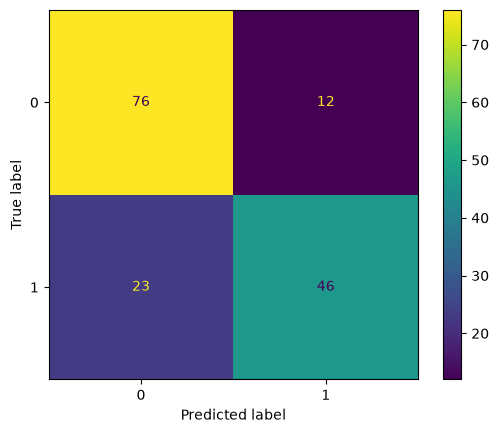

In [181]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("--- Classification Report ---")
report = classification_report(y_test, y_pred)
print('Classification Report:\n')
print(report)

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

The low-level single-neuron model achieved a respectable overall **accuracy of 78%** on the test set. It exhibits a slight bias toward predicting non-survival (higher recall for Class 0), which aligns with the baseline class distribution of the Titanic dataset. For a single-layer architecture trained from scratch using raw gradient descent operations, these evaluation metrics confirm effective convergence and robust decision boundary learning.